# 1. Dataset Exploration

This notebook provides an initial overview of the available ECG signals and their annotations. It inspects the dataset structure, summarizes the metadata, verifies the format of representative `.mat` files, and visualizes raw signals. No preprocessing or model training is performed at this stage.

## 1.1 Library Imports

The libraries required for this exploration are imported here. `pandas` is used to load and inspect the annotation table, `scipy.io.loadmat` reads MATLAB `.mat` files, `NumPy` handles signal arrays, `matplotlib` creates the plots, and `Path` provides platform-independent file paths. The plotting style is also configured in the following code cell.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import loadmat

# Set a simple style to keep the plots readable.
plt.style.use("seaborn-v0_8-whitegrid")

## 1.2 Loading the Annotation File

The `all_anotaciones.csv` file is loaded and its basic structure is inspected. The code first verifies that the annotation file and the directory containing the signal files exist. It then reports the table dimensions, displays representative rows, lists the available columns and their data types, and counts missing values. These checks establish whether the metadata can be used reliably in later stages.

In [ ]:
signals_path = Path("data") / "all_signals"
annotations_path = Path("data") / "all_anotaciones.csv"

# Check that the main paths exist before continuing.
if not annotations_path.is_file():
    raise FileNotFoundError(
        f"No existe el archivo: {annotations_path}"
    )

if not signals_path.is_dir():
    raise FileNotFoundError(
        f"No existe la carpeta: {signals_path}"
    )

# Read the CSV and store it in a pandas DataFrame.
annotations_df = pd.read_csv(
    annotations_path,
    sep=None, # pandas automatically detects the separator
    engine="python",
)

print(f"Loaded file: {annotations_path}")
print(f"Shape: {annotations_df.shape}")

print("\nFirst rows:")
display(annotations_df.head())

print("\nColumn names:")
print(annotations_df.columns.tolist())

print("\nData types:")
display(annotations_df.dtypes.to_frame(name="tipo"))

print("\nMissing values by column:")
null_counts = annotations_df.isna().sum()
display(null_counts.to_frame(name="valores_nulos"))

Archivo cargado: data/all_anotaciones.csv
Dimensiones: (10592, 4)

Primeras filas:


,Unnamed: 0,Nombre,Leads,Anotacion
0,911,BH0002_1_1013721,V5,1
1,1113,BH0002_1_1013721,V6,1
2,1114,BH0002_1_1029081,V6,1
3,912,BH0002_1_1029081,V5,1
4,1115,BH0002_1_1043831,V6,1



Nombres de las columnas:
['Unnamed: 0', 'Nombre', 'Leads', 'Anotacion']

Tipos de datos:


,tipo
Unnamed: 0,int64
Nombre,str
Leads,str
Anotacion,int64



Valores nulos por columna:


,valores_nulos
Unnamed: 0,0
Nombre,0
Leads,0
Anotacion,0


## 1.3 General Statistics

This section summarizes the number of signals, patients, annotation classes, leads, and signals per patient. Together, these summaries provide a first quantitative description of the dataset and help reveal potential class or patient-level imbalances.

The actual column names are displayed before they are used. If a version of the CSV uses different names, the corresponding references should be adjusted in the code cell before running the analysis.

In [3]:
# Display the actual CSV columns.
print("Available columns:")
print(annotations_df.columns.tolist())

# Extract the patient identifier from the "Nombre" column.
# Example:
# BH0002_1_1013721 -> BH0002
annotations_df["patient_id"] = (
    annotations_df["Nombre"]
    .str.split("_")
    .str[0]
)

# Each CSV row corresponds to one ECG signal.
number_of_signals = len(annotations_df)

# Count distinct patients using only the BH00xx code.
number_of_patients = annotations_df["patient_id"].nunique()

print(f"Total number of signals: {number_of_signals:,}")
print(f"Number of distinct patients: {number_of_patients:,}")

Columnas disponibles:
['Unnamed: 0', 'Nombre', 'Leads', 'Anotacion']
Número total de señales: 10,592
Número de pacientes distintos: 33


In [4]:
# Class distribution
class_counts = (
    annotations_df["Anotacion"]
    .value_counts()
    .sort_index()
)

class_percentages = (
    100 * class_counts / len(annotations_df)
)

class_summary = pd.DataFrame(
    {
        "number_of_signals": class_counts,
        "percentage": class_percentages.round(2),
    }
)

print("Class distribution:")
display(class_summary)

Distribución de clases:


,number_of_signals,percentage
Anotacion,,
1,2011,18.99
99,8581,81.01


In [5]:
# Leads
lead_counts = (
    annotations_df["Leads"]
    .value_counts()
    .sort_index()
)

print("Distribution by lead:")
display(
    lead_counts.to_frame(
        name="number_of_signals"
    )
)

Distribución por derivación:


,number_of_signals
Leads,
V1,1762
V2,1773
V3,1765
V4,1758
V5,1772
V6,1762


In [6]:
# Signals per patient in the CSV
signals_per_patient = (
    annotations_df["patient_id"]
    .value_counts()
    .sort_index()
)

print("Number of signals per patient (in CSV):")
display(
    signals_per_patient.to_frame(
        name="number_of_signals"
    )
)

Número de señales por paciente (en csv):


,number_of_signals
patient_id,
BH0002,2759
BH0003,612
BH0004,126
BH0005,246
BH0006,252
BH0007,87
BH0008,126
BH0009,51
BH0010,196


## 1.4 Exploring a `.mat` File

The number of available `.mat` files is counted, and the first file is selected as a representative example. Because each file is expected to contain one ECG signal, the code checks whether the signal is stored under the key `ecg_signal` or `ecg_guardar`. It then reports the selected key, data type, shape, and number of samples, and verifies that the signal is a one-dimensional vector. The sampling frequency is intentionally not assumed because it is not provided by the dataset.

In [ ]:
# Search for .mat files directly inside all_signals.
# Do not interpret or modify their complete filenames.
mat_files = sorted(
    signals_path.glob("*.mat")
)

if len(mat_files) == 0:
    raise FileNotFoundError(
        "No se encontraron archivos .mat "
        "en all_signals."
    )

print(
    f"Number of .mat files found: "
    f"{len(mat_files):,}"
)

# Select the first file in the list as an example.
example_mat_path = mat_files[0]

print(
    f"Example file: "
    f"{example_mat_path}"
)

# loadmat returns a dictionary containing the variables
# stored in MATLAB.
mat_data = loadmat(
    example_mat_path,
    squeeze_me=True,
)

# Keys that start with "__" are MATLAB metadata.
mat_keys = [
    key
    for key in mat_data
    if not key.startswith("__")
]

print(
    f"Data keys in the file: "
    f"{mat_keys}"
)

# The signal variable must have one of these two names.
if "ecg_signal" in mat_data:
    signal_key = "ecg_signal"
elif "ecg_guardar" in mat_data:
    signal_key = "ecg_guardar"
else:
    raise KeyError(
        "ecg_signal not found"
        "neither ecg_guardar in the archive."
    )

# Convert the variable to a NumPy array.
ecg_signal = np.asarray(
    mat_data[signal_key]
)

print(
    f"Signal key used for loading: "
    f"{signal_key}"
)

print(
    f"Data type: "
    f"{ecg_signal.dtype}"
)

print(
    f"Shape: "
    f"{ecg_signal.shape}"
)

print(
    f"Number of samples: "
    f"{ecg_signal.size:,}"
)

# The signal must be a one-dimensional vector.
if ecg_signal.ndim != 1:
    raise ValueError(
        "La señal no tiene formato vectorial 1D."
    )

print("The signal has a 1D vector format.")
print(
    "Sampling frequency: not assumed "
    "because it is not specified."
)

Número de archivos .mat encontrados: 10,592
Archivo de ejemplo: data/all_signals/Para_alumna_Brugada\all_signals\BH0002_1_101372_1_V1_99.mat
Claves de datos del archivo: ['ecg_signal']
Clave utilizada para cargar la señal: ecg_signal
Tipo de datos: float64
Dimensiones: (801,)
Número de muestras: 801
La señal tiene formato vectorial 1D.
Frecuencia de muestreo: no se asume porque no está especificada.


## 1.5 ECG Signal Visualization

The representative ECG signal is plotted in its original form, without filtering, resampling, normalization, or any other transformation. Since the sampling frequency is not known, the horizontal axis is expressed as sample number rather than time. This plot provides a direct visual check of the raw waveform and its amplitude variation.

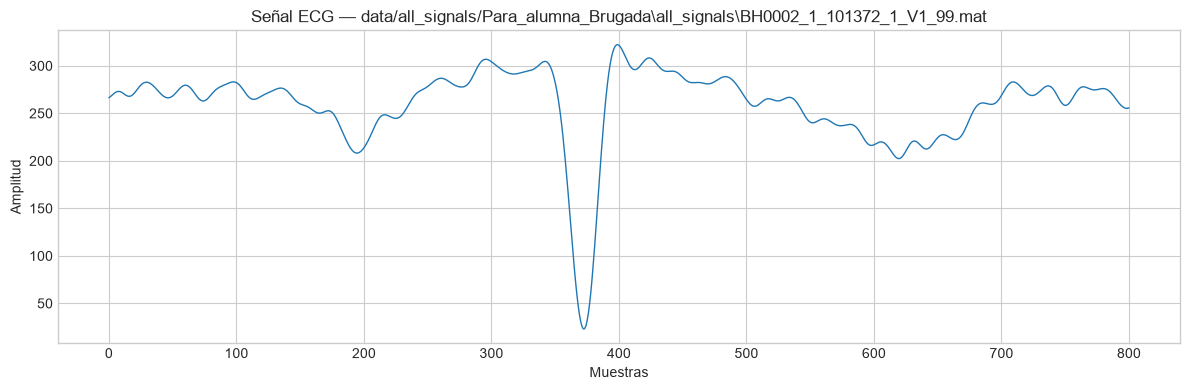

In [8]:
# Each vector position corresponds to one beat sample.
sample_numbers = np.arange(
    len(ecg_signal)
)

plt.figure(figsize=(12, 4))

plt.plot(
    sample_numbers,
    ecg_signal,
    linewidth=1,
)

plt.title(
    f"Señal ECG — {example_mat_path}"
)

plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

### Comparing Individual Beats Across Leads

Up to six files are selected deterministically from the sorted file list, and one signal from each file is plotted in a separate subplot. This comparison provides a visual overview of beat-to-beat or lead-to-lead variability while preserving the original signal values. The figure is kept compact so that the waveforms remain readable.

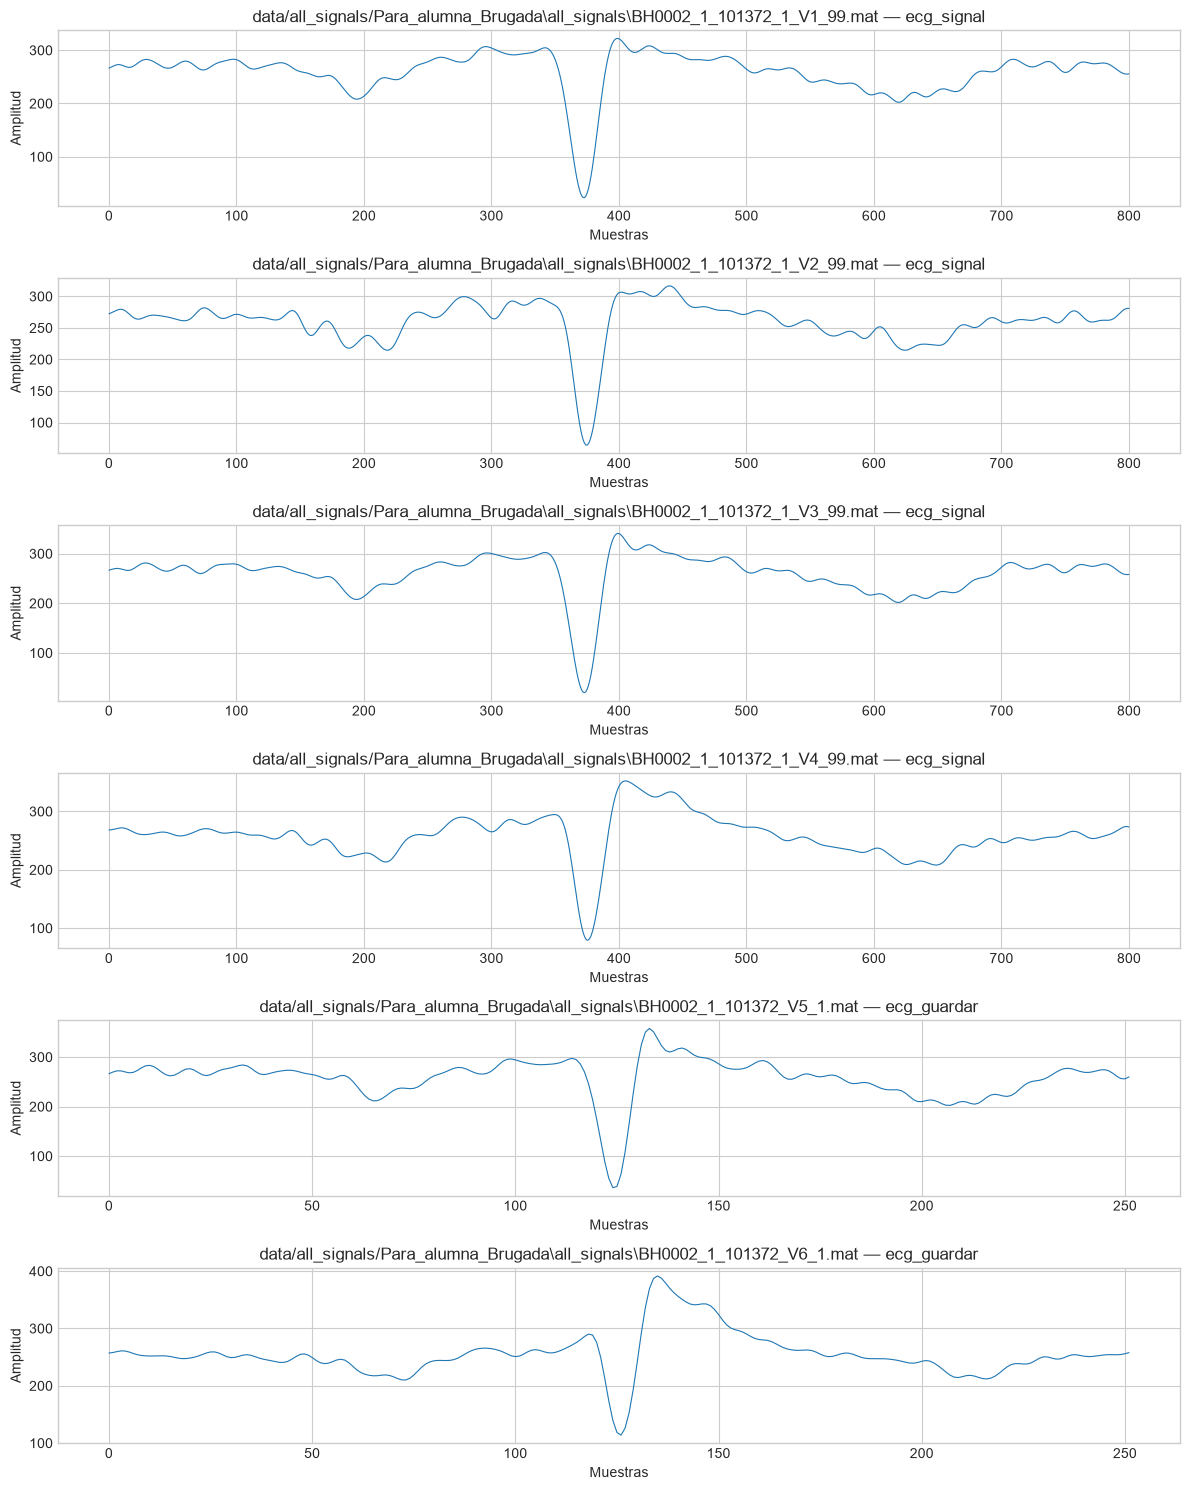

In [9]:
# Select at most six files so that the figure remains readable.
number_of_examples = min(
    6,
    len(mat_files),
)

selected_mat_files = mat_files[
    :number_of_examples
]

plt.figure(
    figsize=(12, 2.5 * number_of_examples)
)

for plot_number, mat_path in enumerate(
    selected_mat_files,
    start=1,
):
    # Load a file and select its known signal variable.
    current_mat_data = loadmat(
        mat_path,
        squeeze_me=True,
    )

    if "ecg_signal" in current_mat_data:
        current_signal_key = "ecg_signal"
    elif "ecg_guardar" in current_mat_data:
        current_signal_key = "ecg_guardar"
    else:
        raise KeyError(
            f"No se encontró la señal en {mat_path}"
        )

    current_ecg_signal = np.asarray(
        current_mat_data[current_signal_key]
    )

    if current_ecg_signal.ndim != 1:
        raise ValueError(
            f"La señal no es 1D: {mat_path}"
        )

    sample_numbers = np.arange(
        len(current_ecg_signal)
    )

    plt.subplot(
        number_of_examples,
        1,
        plot_number,
    )

    plt.plot(
        sample_numbers,
        current_ecg_signal,
        linewidth=0.8,
    )

    plt.title(
        f"{mat_path} — {current_signal_key}"
    )

    plt.xlabel("Muestras")
    plt.ylabel("Amplitud")
    plt.grid(True)

plt.tight_layout()
plt.show()

## 1.6 Initial Conclusions

The exploratory analysis confirms the main organization of the dataset: the annotation table links ECG recordings to patients, leads, and annotation classes, while the signal files store the corresponding raw waveforms. The structural checks also verify the expected one-dimensional signal format and highlight that the sampling frequency must be obtained from external metadata before interpreting the horizontal axis as time.

These observations provide the basis for the next stage of the project, where preprocessing, quality checks, and model development can be designed using the verified dataset structure.